# Actividad 5 — Entrenamiento, optimización y trazabilidad con MLflow

**Dataset:** Breast Cancer Wisconsin (Diagnostic) — scikit-learn / UCI.  
**Algoritmos:** Regresión logística y Random Forest.  
**Validación:** StratifiedKFold (5) y GridSearchCV.  
**Reproducibilidad:** semilla fija 42, escalado dentro del Pipeline y conjunto de prueba reservado.

> El archivo `fuentes/train.py` del repositorio implementa el mismo flujo por separado.

## 1. Instalación de dependencias

In [24]:
%pip -q install "mlflow>=3,<4" "scikit-learn>=1.5,<2" "pandas>=2,<3" "numpy>=1.26,<3"

## 2. Importaciones y versiones

In [25]:
import sys, json, hashlib, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import sklearn
import mlflow
import mlflow.sklearn
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from IPython.display import display

print({'python': sys.version.split()[0], 'pandas': pd.__version__, 'sklearn': sklearn.__version__, 'mlflow': mlflow.__version__})

{'python': '3.13.16', 'pandas': '2.2.3', 'sklearn': '1.6.1', 'mlflow': '3.17.2'}


## 3. Dataset original y versionamiento de datos

In [26]:
Path('datos/datos_ini').mkdir(parents=True, exist_ok=True)
Path('datos/datos_limp').mkdir(parents=True, exist_ok=True)
Path('resultados').mkdir(exist_ok=True)

raw = load_breast_cancer()
df_original = pd.DataFrame(raw.data, columns=raw.feature_names)
df_original['target'] = raw.target.astype(int)
ruta_original = Path('datos/datos_ini/breast_cancer_original.csv')
df_original.to_csv(ruta_original, index=False)
print('Dimensiones originales:', df_original.shape)
print('Clases: 0 = maligno, 1 = benigno')
display(df_original.head())

Dimensiones originales: (569, 31)
Clases: 0 = maligno, 1 = benigno


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


## 4. Validación y limpieza de datos

In [27]:
def preparar_datos(ruta_entrada, ruta_salida):
    df = pd.read_csv(ruta_entrada)
    assert 'target' in df.columns, 'Falta la columna target'
    print('Nulos antes de limpieza:', int(df.isna().sum().sum()))
    print('Duplicados antes de limpieza:', int(df.duplicated().sum()))
    df = df.drop_duplicates().copy()
    features = df.columns.drop('target')
    df[features] = df[features].apply(pd.to_numeric, errors='raise')
    df['target'] = pd.to_numeric(df['target'], errors='raise')
    if df.isna().any().any():
        raise ValueError('Se detectaron valores nulos; requieren tratamiento explícito')
    if not df['target'].isin([0, 1]).all():
        raise ValueError('La variable objetivo contiene clases inválidas')
    df['target'] = df['target'].astype(int)
    df.to_csv(ruta_salida, index=False)
    return df

ruta_limpia = Path('datos/datos_limp/breast_cancer_limpio.csv')
df = preparar_datos(ruta_original, ruta_limpia)
print('Dimensiones finales:', df.shape)
print('Tipos de datos:', df.dtypes.value_counts().to_dict())

def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

versiones = {'dataset_original_sha256': sha256(ruta_original), 'dataset_limpio_sha256': sha256(ruta_limpia)}
Path('resultados/versiones_datos.json').write_text(json.dumps(versiones, indent=2), encoding='utf-8')
print(versiones)

Nulos antes de limpieza: 0
Duplicados antes de limpieza: 0
Dimensiones finales: (569, 31)
Tipos de datos: {dtype('float64'): 30, dtype('int64'): 1}
{'dataset_original_sha256': '75a1d74a59df9cb0a78ecc0a36085bf8a85239557f178d3b8d758e88b26416e1', 'dataset_limpio_sha256': '75a1d74a59df9cb0a78ecc0a36085bf8a85239557f178d3b8d758e88b26416e1'}


## 5. Separación de datos y configuración de modelos

La optimización se realiza **solo** sobre entrenamiento; el conjunto de prueba se utiliza al final. La métrica F1 estándar corresponde a la clase **benigna (1)**. También se calcula recall de la clase **maligna (0)**.

In [28]:
X = df.drop(columns='target')
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
configuraciones = {
    'Regresion_Logistica': (
        Pipeline([('scaler', StandardScaler()), ('modelo', LogisticRegression(max_iter=2000, random_state=42))]),
        {'modelo__C': [0.01, 0.1, 1, 10, 100]}
    ),
    'Random_Forest': (
        RandomForestClassifier(random_state=42),
        {'n_estimators': [50, 100, 200], 'max_depth': [None, 5, 10], 'min_samples_split': [2, 5]}
    )
}
print('Entrenamiento:', X_train.shape, 'Prueba:', X_test.shape)

Entrenamiento: (455, 30) Prueba: (114, 30)


## 6. Configurar MLflow con SQLite

Cada ejecución crea nuevos *runs* para conservar el historial. El backend SQLite evita el error del almacenamiento basado en archivos.

In [29]:
Path('mlflow_data').mkdir(exist_ok=True)
mlflow.set_tracking_uri((Path('mlflow_data/mlflow.db').resolve()).as_uri().replace('file:///', 'sqlite:///') if False else 'sqlite:///' + str(Path('mlflow_data/mlflow.db').resolve()))
experimento = mlflow.set_experiment('Actividad5_Comparacion_Modelos')
print('Tracking URI:', mlflow.get_tracking_uri())
print('ID experimento:', experimento.experiment_id)

Tracking URI: sqlite:////content/mlflow_data/mlflow.db
ID experimento: 1


## 7. GridSearchCV, evaluación y registro automático

Se registra cada modelo con sus hiperparámetros, métricas, huella de datos y artefactos. Para el árbol de Random Forest se autoriza **únicamente** el tipo de Scikit-learn producido localmente.

In [30]:
resultados = {}
for nombre, (estimador, grilla) in configuraciones.items():
    print('\nEntrenando:', nombre)
    busqueda = GridSearchCV(estimador, grilla, scoring='f1', cv=cv, n_jobs=-1, refit=True)
    busqueda.fit(X_train, y_train)
    modelo = busqueda.best_estimator_
    pred = modelo.predict(X_test)
    proba = modelo.predict_proba(X_test)[:, 1]
    metricas = {
        'accuracy': accuracy_score(y_test, pred),
        'precision': precision_score(y_test, pred, pos_label=1),
        'recall': recall_score(y_test, pred, pos_label=1),
        'f1_score': f1_score(y_test, pred, pos_label=1),
        'roc_auc': roc_auc_score(y_test, proba),
        'cv_f1': busqueda.best_score_,
        'recall_maligno': recall_score(y_test, pred, pos_label=0)
    }
    resultados[nombre] = metricas
    with mlflow.start_run(run_name=f'{nombre}_GridSearch') as run:
        mlflow.log_params({'algoritmo': nombre, 'cv_folds': 5, 'test_size': 0.20, 'random_state': 42})
        mlflow.log_params({k: str(v) for k, v in busqueda.best_params_.items()})
        mlflow.log_metrics({k: float(v) for k, v in metricas.items()})
        mlflow.set_tags({'dataset_sha256': versiones['dataset_limpio_sha256'], 'sklearn_version': sklearn.__version__})
        mlflow.log_dict({'matriz_confusion': confusion_matrix(y_test, pred).tolist(), 'orden_clases': [0, 1]}, 'evaluacion/matriz_confusion.json')
        kwargs = {'skops_trusted_types': ['sklearn.tree._tree.Tree']} if nombre == 'Random_Forest' else {}
        mlflow.sklearn.log_model(sk_model=modelo, name='modelo_entrenado', **kwargs)
        print('Run ID:', run.info.run_id)
    print('Mejores parámetros:', busqueda.best_params_)
    print('Métricas:', {k: round(float(v), 4) for k, v in metricas.items()})


Entrenando: Regresion_Logistica
Run ID: f8ded92033b34c88a807bf285a38898c
Mejores parámetros: {'modelo__C': 0.1}
Métricas: {'accuracy': 0.9737, 'precision': 0.9726, 'recall': 0.9861, 'f1_score': 0.9793, 'roc_auc': 0.9957, 'cv_f1': 0.9861, 'recall_maligno': 0.9524}

Entrenando: Random_Forest
Run ID: 754a2850fd8049008320e6a9dac20d57
Mejores parámetros: {'max_depth': 5, 'min_samples_split': 5, 'n_estimators': 200}
Métricas: {'accuracy': 0.9561, 'precision': 0.9589, 'recall': 0.9722, 'f1_score': 0.9655, 'roc_auc': 0.9927, 'cv_f1': 0.9702, 'recall_maligno': 0.9286}


## 8. Comparación de resultados

In [31]:
tabla = pd.DataFrame(resultados).T
ruta_resultados = Path('resultados/resultados_finales.csv')
tabla.to_csv(ruta_resultados, index_label='modelo')
display(tabla.round(4))
print('Mejor modelo por F1 en prueba:', tabla['f1_score'].idxmax())
print('Nota: seleccionar por prueba es descriptivo; para selección formal usar validación cruzada.')

,accuracy,precision,recall,f1_score,roc_auc,cv_f1,recall_maligno
Regresion_Logistica,0.9737,0.9726,0.9861,0.9793,0.9957,0.9861,0.9524
Random_Forest,0.9561,0.9589,0.9722,0.9655,0.9927,0.9702,0.9286


Mejor modelo por F1 en prueba: Regresion_Logistica
Nota: seleccionar por prueba es descriptivo; para selección formal usar validación cruzada.


## 9. Comprobación de los registros de MLflow

In [32]:
runs = mlflow.search_runs(experiment_ids=[experimento.experiment_id])
columnas = ['run_id', 'tags.mlflow.runName', 'metrics.f1_score', 'metrics.cv_f1', 'metrics.recall_maligno']
display(runs[columnas].head(10))
assert len(runs) >= 2, 'Deben existir al menos dos ejecuciones'
print('Verificación completada.')

,run_id,tags.mlflow.runName,metrics.f1_score,metrics.cv_f1,metrics.recall_maligno
0,754a2850fd8049008320e6a9dac20d57,Random_Forest_GridSearch,0.965517,0.970181,0.928571
1,f8ded92033b34c88a807bf285a38898c,Regresion_Logistica_GridSearch,0.979310,0.986116,0.952381
2,386611481eed4ecfaabdfcd1d3e4695b,Random_Forest_GridSearch,0.965517,0.970181,0.928571
3,b29133b421814ac6b98d017cf96dbb6c,Regresion_Logistica_GridSearch,0.979310,0.986116,0.952381


Verificación completada.


## 10. Exportar evidencia y respaldo


In [33]:
# Incluir datos, resultados y base de experimentos en un ZIP.
shutil.make_archive('Actividad5_evidencias', 'zip', root_dir='.', base_dir='datos')
# ZIP separado para MLflow y resultados, sin modificar la base de datos.
import zipfile
with zipfile.ZipFile('Actividad5_mlflow_resultados.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for carpeta in ['mlflow_data', 'resultados']:
        for p in Path(carpeta).rglob('*'):
            if p.is_file(): z.write(p)
print('Archivos creados: Actividad5_evidencias.zip y Actividad5_mlflow_resultados.zip')
# En Colab, descarga manualmente desde el panel Archivos o descomenta:
# from google.colab import files
# files.download('Actividad5_mlflow_resultados.zip')

Archivos creados: Actividad5_evidencias.zip y Actividad5_mlflow_resultados.zip


# 11. Evidencia gráfica

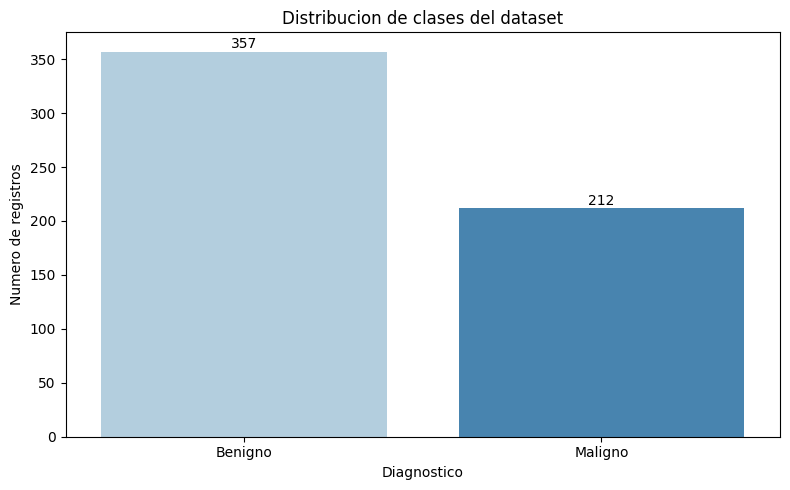

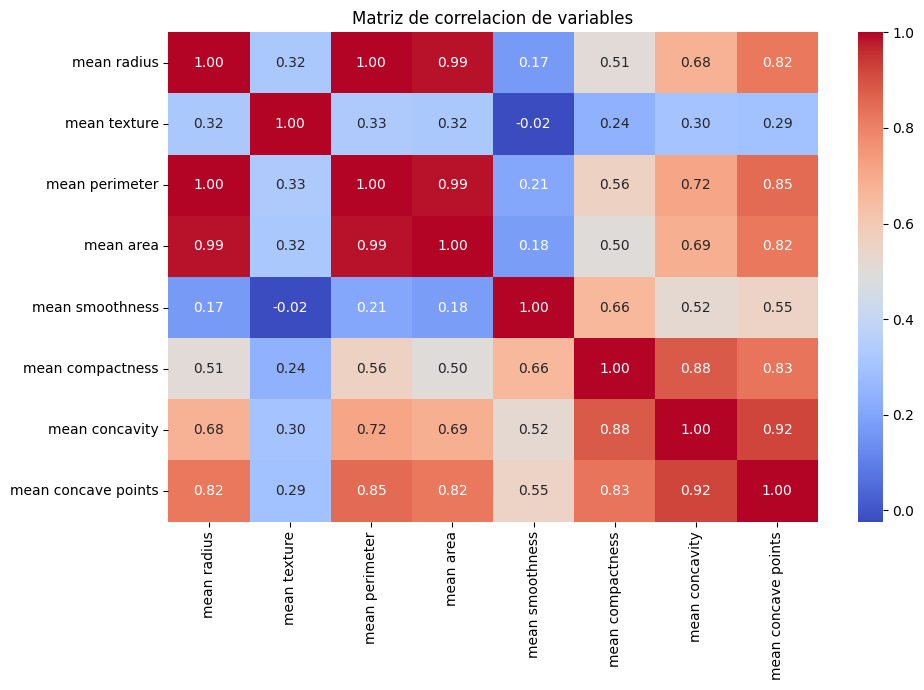

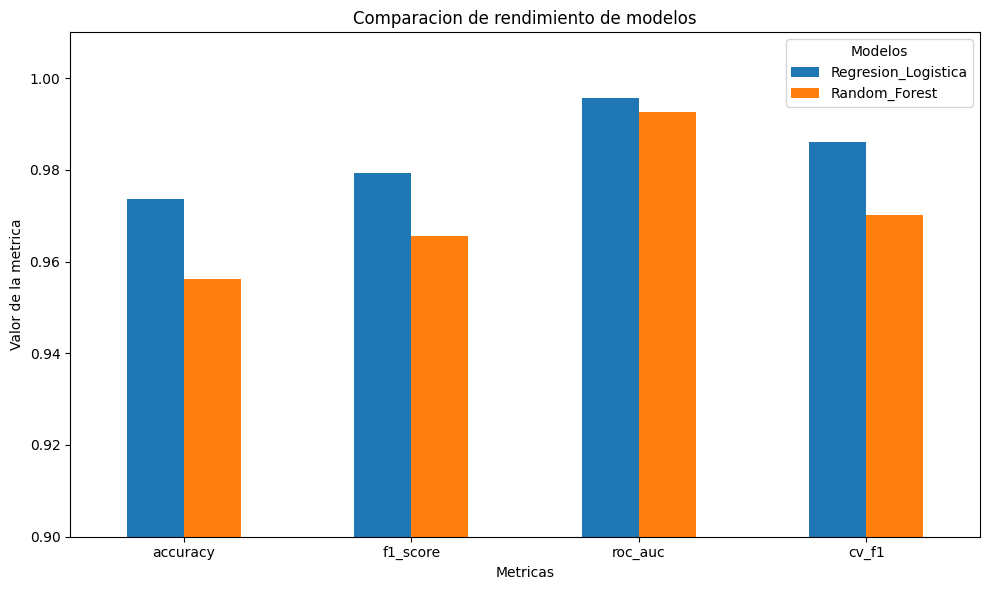

Grafica comparativa generada correctamente


In [34]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Carpeta para guardar evidencias
Path("evidencias").mkdir(exist_ok=True)

# Cargar dataset limpio
df = pd.read_csv("datos/datos_limp/breast_cancer_limpio.csv")

# Grafica 1: Distribucion de clases
conteo = df["target"].map({
    0: "Maligno",
    1: "Benigno"
}).value_counts()

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    x=conteo.index,
    y=conteo.values,
    hue=conteo.index,
    palette="Blues",
    legend=False
)

for i, valor in enumerate(conteo.values):
    ax.text(i, valor + 3, str(valor), ha="center")

plt.title("Distribucion de clases del dataset")
plt.xlabel("Diagnostico")
plt.ylabel("Numero de registros")
plt.tight_layout()
plt.savefig("evidencias/distribucion_clases.png", dpi=300)
plt.show()

# Grafica 2: Correlacion de variables
columnas = [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean area",
    "mean smoothness",
    "mean compactness",
    "mean concavity",
    "mean concave points"
]

plt.figure(figsize=(10, 7))
sns.heatmap(
    df[columnas].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Matriz de correlacion de variables")
plt.tight_layout()
plt.savefig("evidencias/matriz_correlacion.png", dpi=300)
plt.show()

# Grafica 3: Comparacion de modelos
import pandas as pd
import matplotlib.pyplot as plt

metricas = ["accuracy", "f1_score", "roc_auc", "cv_f1"]

# Recuperar resultados de la ejecucion anterior
if "resultados_finales" in globals():
    df_comparacion = pd.DataFrame(resultados_finales).T

elif "resultados" in globals():
    df_comparacion = pd.DataFrame(resultados).T

# Alternativa: cargar resultados guardados
elif "df_final" in globals():
    df_comparacion = df_final.copy()

elif Path("resultados/resultados_finales.csv").exists():
    df_comparacion = pd.read_csv(
        "resultados/resultados_finales.csv",
        index_col=0
    )

else:
    raise FileNotFoundError(
        "No se encontraron resultados finales. "
        "Ejecuta primero el entrenamiento o carga el CSV."
    )

# Seleccionar metricas
comparacion = df_comparacion[metricas].T

# Generar grafica
ax = comparacion.plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0.90, 1.01),
    rot=0
)

plt.title("Comparacion de rendimiento de modelos")
plt.ylabel("Valor de la metrica")
plt.xlabel("Metricas")
plt.legend(title="Modelos")
plt.tight_layout()

# Guardar evidencia
Path("evidencias").mkdir(exist_ok=True)
plt.savefig(
    "evidencias/comparacion_modelos.png",
    dpi=300
)

plt.show()

print("Grafica comparativa generada correctamente")


In [35]:
import shutil
from google.colab import files

shutil.make_archive(
    "evidencias_graficas",
    "zip",
    "evidencias"
)

files.download("evidencias_graficas.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [36]:

import mlflow
import pandas as pd
from pathlib import Path

# Crear carpeta de evidencias
Path("evidencias").mkdir(exist_ok=True)

# Consultar experimento
experimento = mlflow.get_experiment_by_name(
    "Actividad5_Comparacion_Modelos"
)

if experimento is None:
    raise ValueError("No se encontro el experimento")

# Recuperar ejecuciones
runs = mlflow.search_runs(
    experiment_ids=[experimento.experiment_id]
)

# Seleccionar informacion relevante
columnas = [
    "tags.mlflow.runName",
    "params.algoritmo",
    "metrics.accuracy",
    "metrics.precision",
    "metrics.recall",
    "metrics.f1_score",
    "metrics.roc_auc",
    "metrics.cv_f1",
    "metrics.recall_maligno"
]

# Mostrar y guardar resultados
tabla = runs[columnas].copy()

display(tabla)

tabla.to_csv(
    "evidencias/mlflow_experimentos.csv",
    index=False
)

print("Evidencia de MLflow exportada correctamente")


,tags.mlflow.runName,params.algoritmo,metrics.accuracy,metrics.precision,metrics.recall,metrics.f1_score,metrics.roc_auc,metrics.cv_f1,metrics.recall_maligno
0,Random_Forest_GridSearch,Random_Forest,0.956140,0.958904,0.972222,0.965517,0.992725,0.970181,0.928571
1,Regresion_Logistica_GridSearch,Regresion_Logistica,0.973684,0.972603,0.986111,0.979310,0.995701,0.986116,0.952381
2,Random_Forest_GridSearch,Random_Forest,0.956140,0.958904,0.972222,0.965517,0.992725,0.970181,0.928571
3,Regresion_Logistica_GridSearch,Regresion_Logistica,0.973684,0.972603,0.986111,0.979310,0.995701,0.986116,0.952381


Evidencia de MLflow exportada correctamente


In [37]:
import mlflow
import pandas as pd
from pathlib import Path
from mlflow.tracking import MlflowClient

Path("evidencias").mkdir(exist_ok=True)

cliente = MlflowClient()

experimento = mlflow.get_experiment_by_name(
    "Actividad5_Comparacion_Modelos"
)

if experimento is None:
    raise ValueError("No se encontró el experimento")

runs = mlflow.search_runs(
    experiment_ids=[experimento.experiment_id]
)

registros = []

for _, fila in runs.iterrows():
    run_id = fila["run_id"]
    run = cliente.get_run(run_id)

    # Consultar modelos registrados en MLflow
    modelos = cliente.search_logged_models(
        experiment_ids=[experimento.experiment_id],
        filter_string=f"source_run_id = '{run_id}'"
    )

    registros.append({
        "run_id": run_id,
        "algoritmo": run.data.params.get("algoritmo"),
        "hiperparametros": str(run.data.params),
        "f1_score": run.data.metrics.get("f1_score"),
        "cv_f1": run.data.metrics.get("cv_f1"),
        "modelos_registrados": len(modelos),
        "modelos_ids": str([
            modelo.model_id for modelo in modelos
        ])
    })

df_evidencia = pd.DataFrame(registros)

display(df_evidencia)

df_evidencia.to_csv(
    "evidencias/mlflow_trazabilidad.csv",
    index=False
)

print("Evidencia de trazabilidad exportada correctamente")

,run_id,algoritmo,hiperparametros,f1_score,cv_f1,modelos_registrados,modelos_ids
0,754a2850fd8049008320e6a9dac20d57,Random_Forest,"{'algoritmo': 'Random_Forest', 'cv_folds': '5'...",0.965517,0.970181,1,['m-e2637a6568e24aa8b0c996782ed97552']
1,f8ded92033b34c88a807bf285a38898c,Regresion_Logistica,"{'algoritmo': 'Regresion_Logistica', 'cv_folds...",0.979310,0.986116,1,['m-a5be0c85a8334a6d8285c935a519c26b']
2,386611481eed4ecfaabdfcd1d3e4695b,Random_Forest,"{'algoritmo': 'Random_Forest', 'cv_folds': '5'...",0.965517,0.970181,1,['m-02e5e307882441bf96fdfff5274d9c06']
3,b29133b421814ac6b98d017cf96dbb6c,Regresion_Logistica,"{'algoritmo': 'Regresion_Logistica', 'cv_folds...",0.979310,0.986116,1,['m-316c2381185540879612d1af724491f7']


Evidencia de trazabilidad exportada correctamente


In [38]:
import shutil
from pathlib import Path
from google.colab import files

carpeta = Path("evidencias")

print("Archivos disponibles:")
for archivo in sorted(carpeta.iterdir()):
    print("-", archivo.name)

shutil.make_archive(
    "Actividad5_Evidencias",
    "zip",
    root_dir=".",
    base_dir="evidencias"
)

files.download("Actividad5_Evidencias.zip")

Archivos disponibles:
- comparacion_modelos.png
- distribucion_clases.png
- matriz_correlacion.png
- mlflow_experimentos.csv
- mlflow_trazabilidad.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Conclusión

Compara los valores reales de la tabla. La validación cruzada estima estabilidad en entrenamiento; el conjunto de prueba permite una evaluación final. En aplicaciones médicas, revisa especialmente el **recall de la clase maligna (0)**.

In [66]:
import subprocess
import time
from pathlib import Path

# 1. Detener procesos activos en los puertos 5000 y 5001
print("Limpiando puertos y servidores MLflow previos...")
subprocess.run(["fuser", "-k", "-n", "tcp", "5000"], check=False)
subprocess.run(["fuser", "-k", "-n", "tcp", "5001"], check=False)
subprocess.run(["pkill", "-9", "-f", "mlflow"], check=False)
time.sleep(3)

# 2. Configurar base de datos local de SQLite
base_datos = Path("mlflow_data/mlflow.db").resolve()
assert base_datos.exists(), "La base de datos SQLite de MLflow no se encuentra en mlflow_data/mlflow.db"

# 3. Lanzar servidor permitiendo todos los hosts y orígenes de CORS (soluciona error 403 en peticiones AJAX)
print("Iniciando servidor de MLflow en el puerto 5000...")
log_servidor = open("/tmp/mlflow_ui_5000.log", "w")

proceso = subprocess.Popen([
    "mlflow", "ui",
    "--backend-store-uri", f"sqlite:///{base_datos}",
    "--host", "127.0.0.1",
    "--port", "5000",
    "--allowed-hosts", "*",
    "--cors-allowed-origins", "*"
], stdout=log_servidor, stderr=subprocess.STDOUT)

time.sleep(5)
if proceso.poll() is None:
    print("¡Servidor MLflow iniciado correctamente en segundo plano!")
else:
    print("Error al iniciar el servidor. Logs:")
    print(Path("/tmp/mlflow_ui_5000.log").read_text())

Limpiando puertos y servidores MLflow previos...
Iniciando servidor de MLflow en el puerto 5000...
¡Servidor MLflow iniciado correctamente en segundo plano!


In [67]:
print("Servidor iniciado:", proceso.pid)
print("Origen autorizado:", origen)

Servidor iniciado: 14247
Origen autorizado: https://5001-gpu-t4-s-ass1c1-21uc2d5axfmau-c.asia-southeast1.prod.r.colab.dev
